# **Frugal AI: Rethinking model design and objective for a sustainable future**

**PSL-Week: Practical work notebook for part 2**

This document presents instructions regarding the second practical work session of the Frugal-AI PSL-Week. All the materials (slides, notebooks, base codes) can be recovered from the corresponding [GitHub repository](https://github.com/Deyht/frugal_ai).

The notebook is expected to be run on a Google Colab environment with a T4 GPU:
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Deyht/frugal_ai/blob/main/frugal_ai_opt_ann_correction.ipynb)


This notebook is **not intended as a standalone** document; the slides should be used as a reference to understand several of the explanations provided in the analysis of the results.

# Energy budget based CNN base optimization on GPU

This part addresses the optimization of Artificial Neural Network models for numerical efficiency and, therefore, energy efficiency.

For this exercise, we will use the ASIRRA (Animal Species Image Recognition for Restricting Access) dataset, which comprises 25000 labeled images of Cats and Dogs. The objective is to explore network structures, following the lecture's guidelines, to build a classification model that **maximizes classification accuracy under a given energy budget**. As discussed in the slides, both training and inference contribute to the model's environmental budget. To simplify the problem so it is compatible with a practical work session, we will assume the model's training cost is negligible and account only for electricity consumption during inference (which would match a long-lasting, broadly distributed model). We will also not factor in any infrastructure cost. Those are very strong approximations, and we invite the participants to refer back to the slide for a more complete view of the impact of ITC systems. At the end, **for our practical case, we consider that the energy consumed is simply proportional to the execution time**.

This practical work will be carried out through Google Colab, granting each participant access to an Nvidia T4 GPU (Turing, 2560 CUDA cores, 16 GB RAM, peak FP32: 8.141 TFLOPS, and FP16: 65.13 TFLOPS, 70W peak consumption). Our energy budget will be based on the compute time required to process a set of 2048 test images, with a maximum budget of 300 ms. Your objective will be to design a model that achieves the highest possible classification accuracy (maximizing usefulness) while remaining under this budget. Note that a model reaching only 80% accuracy on this task (1 error out of 5 predictions) can barely be considered useful.

The default version of this notebook handles the data loading, model training, and inference for a simple LeNET-5-like architecture. The ANN model is built and trained using the custom [CIANNA](https://github.com/Deyht/CIANNA) framework. You should be able to adapt the architecture with only minor adjustments to the appropriate notebook cells, taking inspiration from the provided example. You can refer to CIANNA's WIKI page for a complete framework description and access to the full list of supported layers and their configurations. You can also look at some example scripts provided in CIANNA's GitHub repository. Of course, you are also free to replace these parts with any other Deep Learning development framework you are familiar with (TensorFlow, PyTorch, etc.), as long as you correctly measure the inference time using a T4 GPU over Google Colab.

### **CIANNA installation**

This notebook uses CIANNA to build and train network architectures. CIANNA is a general-purpose artificial neural network development framework (like TensorFlow or PyTorch) designed mainly for astronomical applications. Still, it is perfectly usable for classical CNN implementations. It is very fast for small networks, and it provides several performance measurement tools that will be useful in the context of this exercise.

CIANNA is coded in C and CUDA for GPU acceleration and is controlled through a Python interface. As it is not available in Colab by default, we start by installing it.

**Link to the CIANNA github repository**
https://github.com/Deyht/CIANNA

In [1]:
%%bash

#cd /content/
git clone https://github.com/Deyht/CIANNA -b experimental

cd CIANNA
./clean.sh
cmake -B build -DBLA_VENDOR=OpenBLAS
cmake --build build
cd ..

Clonage dans 'CIANNA'...
Mise à jour des fichiers: 100% (53/53), fait.
rm: impossible de supprimer 'main': Aucun fichier ou dossier de ce nom
rm: impossible de supprimer 'mnist.tar.gz': Aucun fichier ou dossier de ce nom
rm: impossible de supprimer 'error.txt': Aucun fichier ou dossier de ce nom
rm: impossible de supprimer '*.o': Aucun fichier ou dossier de ce nom
rm: impossible de supprimer '*.gch': Aucun fichier ou dossier de ce nom
rm: impossible de supprimer 'blas/*.o': Aucun fichier ou dossier de ce nom
rm: impossible de supprimer 'cuda/*.o': Aucun fichier ou dossier de ce nom
rm: impossible de supprimer 'naiv/*.o': Aucun fichier ou dossier de ce nom
rm: impossible de supprimer 'error.txt': Aucun fichier ou dossier de ce nom


-- The C compiler identification is GNU 13.3.0
-- Detecting C compiler ABI info
-- Detecting C compiler ABI info - done
-- Check for working C compiler: /usr/bin/cc - skipped
-- Detecting C compile features
-- Detecting C compile features - done
-- Looking for sgemm_
-- Looking for sgemm_ - found
-- Found BLAS: /usr/lib/x86_64-linux-gnu/libopenblas.so  
-- BLAS_LIBRARIES = /usr/lib/x86_64-linux-gnu/libopenblas.so
-- BLAS_INCLUDE_DIR = /usr/include/x86_64-linux-gnu
-- Found OpenMP_C: -fopenmp (found version "4.5") 
-- Found OpenMP: TRUE (found version "4.5")  
-- Could not find nvcc, please set CUDAToolkit_ROOT.


CUDA toolkit not found, disabling USE_CUDA.
USE_CUDA : OFF


-- Found Python3: /usr/local/miniforge3/envs/simul/bin/python3 (found version "3.13.11") found components: Interpreter Development NumPy Development.Module Development.Embed 
-- Configuring done (7.7s)


CMake Warning at CMakeLists.txt:491 (add_library):
  Cannot generate a safe runtime search path for target cianna_module because
  files in some directories may conflict with libraries in implicit
  directories:

    runtime library [libopenblas.so.0] in /usr/lib/x86_64-linux-gnu may be hidden by files in:
      /usr/local/miniforge3/envs/simul/lib
    runtime library [libgomp.so.1] in /usr/lib/gcc/x86_64-linux-gnu/13 may be hidden by files in:
      /usr/local/miniforge3/envs/simul/lib

  Some of these libraries may not be found correctly.




-- Generating done (0.9s)
-- Build files have been written to: /home/pslweek/ctrinh/frugal_ai/CIANNA/build
[  3%] Building C object CMakeFiles/cianna_module.dir/src/python_module.c.o
[  7%] Building C object CMakeFiles/cianna_module.dir/src/input_layer.c.o
[ 11%] Building C object CMakeFiles/cianna_module.dir/src/dense_layer.c.o
[ 14%] Building C object CMakeFiles/cianna_module.dir/src/conv_layer.c.o
[ 18%] Building C object CMakeFiles/cianna_module.dir/src/pool_layer.c.o
[ 22%] Building C object CMakeFiles/cianna_module.dir/src/norm_layer.c.o
[ 25%] Building C object CMakeFiles/cianna_module.dir/src/lrn_layer.c.o
[ 29%] Building C object CMakeFiles/cianna_module.dir/src/grn_layer.c.o
[ 33%] Building C object CMakeFiles/cianna_module.dir/src/merge_layer.c.o
[ 37%] Building C object CMakeFiles/cianna_module.dir/src/activ_functions.c.o
[ 40%] Building C object CMakeFiles/cianna_module.dir/src/weights_initializers.c.o
[ 44%] Building C object CMakeFiles/cianna_module.dir/src/vars.c.o
[ 48

### **ASIRRA**

The ASIRRA (Animal Species Image Recognition for Restricting Access) dataset was originally used for CAPTCHA and HIP (Human Interactive Proofs).

The original dataset comprises 25000 images of variable resolution (averaging around 350x500) and is evenly distributed over the two classes "Cat" and "Dog". For this exercise, we provide two reduced versions in the form of padded and resized RGB images at either 128x128 or 256x256 as two binary files. This construction is necessary so the dataset can fit into the limited amount of RAM available through the free tier of Colab. You can download one or both sets to test the impact of the input resolution on your network. In these files, the first 12500 images are of Cats, and the next 12500 are of Dogs. The last 1024 images of each class will be excluded to form our reference test dataset (total size 2048).

#### Downloading and visualizing the data

We start by downloading and visualizing the raw data. You can get one or both of the resized versions.

In [1]:
%%bash

cd /content

#wget https://share.obspm.fr/s/tHy9cFjHmJBR6ye/download/asirra_bin_32.dat

wget https://share.obspm.fr/s/pgAcMzP6G2YjNTY/download/asirra_bin_64.dat

#Larger image files are compressed to save some download time
#wget https://share.obspm.fr/s/6TBsCpAASeETH3S/download/asirra_bin_128.tar.gz
#tar -xvzf asirra_bin_128.tar.gz

#wget https://share.obspm.fr/s/52nxyfn7PjzawSe/download/asirra_bin_256.tar.gz
#tar -xvzf asirra_bin_256.tar.gz

bash: ligne 2 : cd: /content: Aucun fichier ou dossier de ce nom
--2026-11-26 14:58:49--  https://share.obspm.fr/s/pgAcMzP6G2YjNTY/download/asirra_bin_64.dat
Résolution de share.obspm.fr (share.obspm.fr)… 145.238.186.112
Connexion à share.obspm.fr (share.obspm.fr)|145.238.186.112|:443… connecté.
requête HTTP transmise, en attente de la réponse… 303 See Other
Emplacement : https://share.obspm.fr/public.php/dav/files/pgAcMzP6G2YjNTY [suivant]
--2026-11-26 14:58:49--  https://share.obspm.fr/public.php/dav/files/pgAcMzP6G2YjNTY
Réutilisation de la connexion existante à share.obspm.fr:443.
requête HTTP transmise, en attente de la réponse… 200 OK
Taille : 307200000 (293M) [application/octet-stream]
Enregistre : ‘asirra_bin_64.dat’

     0K .......... .......... .......... .......... ..........  0% 2,59M 1m53s
    50K .......... .......... .......... .......... ..........  0% 24,0M 63s
   100K .......... .......... .......... .......... ..........  0% 4,67M 63s
   150K .......... .......... .

#### Import and global settings for the noebook (rerun if the kernel crashes)

In [1]:
%%bash

pip install albumentations

Defaulting to user installation because normal site-packages is not writeable


#### Data handling and augmentation

To ease data manipulation and hyperparameter exploration, we first provide a set of helper functions.  
**Every time you want to change the content of these functions, you will need to rerun this cell.**

In [9]:
%%writefile helper.py

import numpy as np
import matplotlib.pyplot as plt
import os, sys, gc, glob, time, cv2
from threading import Thread
from PIL import Image
import albumentations as A

sys.path.insert(0,glob.glob('CIANNA/build/')[-1]) #if compiled with cmake
import CIANNA as cnn

def data_prep(nb_images_per_iter, raw_image_size, image_size, test_mode=0):
  #Data arrays are declared as global so we can work in place to reduce RAM footprint
  global raw_images, input_data, targets, input_val, targets_val

  raw_images = np.reshape(np.fromfile("asirra_bin_%d.dat"%(raw_image_size), dtype="uint8"), (25000, raw_image_size, raw_image_size,3))

  if(test_mode == 0):
    input_data = np.zeros((nb_images_per_iter,3*image_size**2), dtype="float32") #CIANNA expects "float32" arrays
    targets = np.zeros((nb_images_per_iter,2), dtype="float32")

  input_val = np.zeros((2048,3*image_size**2), dtype="float32")
  targets_val = np.zeros((2048,2), dtype="float32")


def create_augmented_batch(A_transform):

  nb_images = np.shape(input_data)[0]

  for i in range(0,nb_images):

    l_class = np.random.randint(0,2)
    l_id = np.random.randint(0,12500 - 1024)
    #Last 1024 images of each class kept only for the val/test set

    patch = raw_images[l_class*12500+l_id]
    transformed = A_transform(image=patch)
    patch_aug = transformed['image']

    l_image_size = np.shape(patch_aug)[0]

    #CIANNA expects data formated as 2D numpy arrays representing a list of flattened images (with every channel flattened after the others)
    for depth in range(0,3): #We normalize based on mean pixel value
      input_data[i,depth*l_image_size**2:(depth+1)*l_image_size**2] = (patch_aug[:,:,depth].flatten("C") - 100.0)/155.0

    targets[i,:] = 0.05 #Label smoothing during training
    targets[i,l_class] = 0.95

  return input_data, targets


def create_validation_set(A_transform):

  for i in range(0,2048):

    l_class = i // 1024

    patch = raw_images[(1+l_class)*(12500 - 1024) + i]
    transformed = A_transform(image=patch)
    patch_aug = transformed['image']

    l_image_size = np.shape(patch_aug)[0]

    for depth in range(0,3):
      input_val[i,depth*l_image_size**2:(depth+1)*l_image_size**2] = (patch_aug[:,:,depth].flatten("C") - 100.0)/155.0

    targets_val[i,:] = 0.0
    targets_val[i,l_class] = 1.0

  return input_val, targets_val


def free_data_helper():
  global raw_images, input_data, targets, input_val, targets_val
  if 'raw_images' in globals():
    del (raw_images)
  if 'input_data' in globals():
    del (input_data)
  if 'targets' in globals():
    del (targets)
  if 'input_val' in globals():
    del (input_val)
  if 'targets_val' in globals():
    del (targets_val)
  gc.collect()
  return

Overwriting helper.py


We can test the helper functions with a simple example and display the produced images. The next cell illustrates how we can create an augmented batch of images for training from the raw image dataset.  

Use this example to test the effect of combining different transform operations for data augmentation. You can also test the impact of the image resolution and of the position of the resize transformation in the augmentation list.

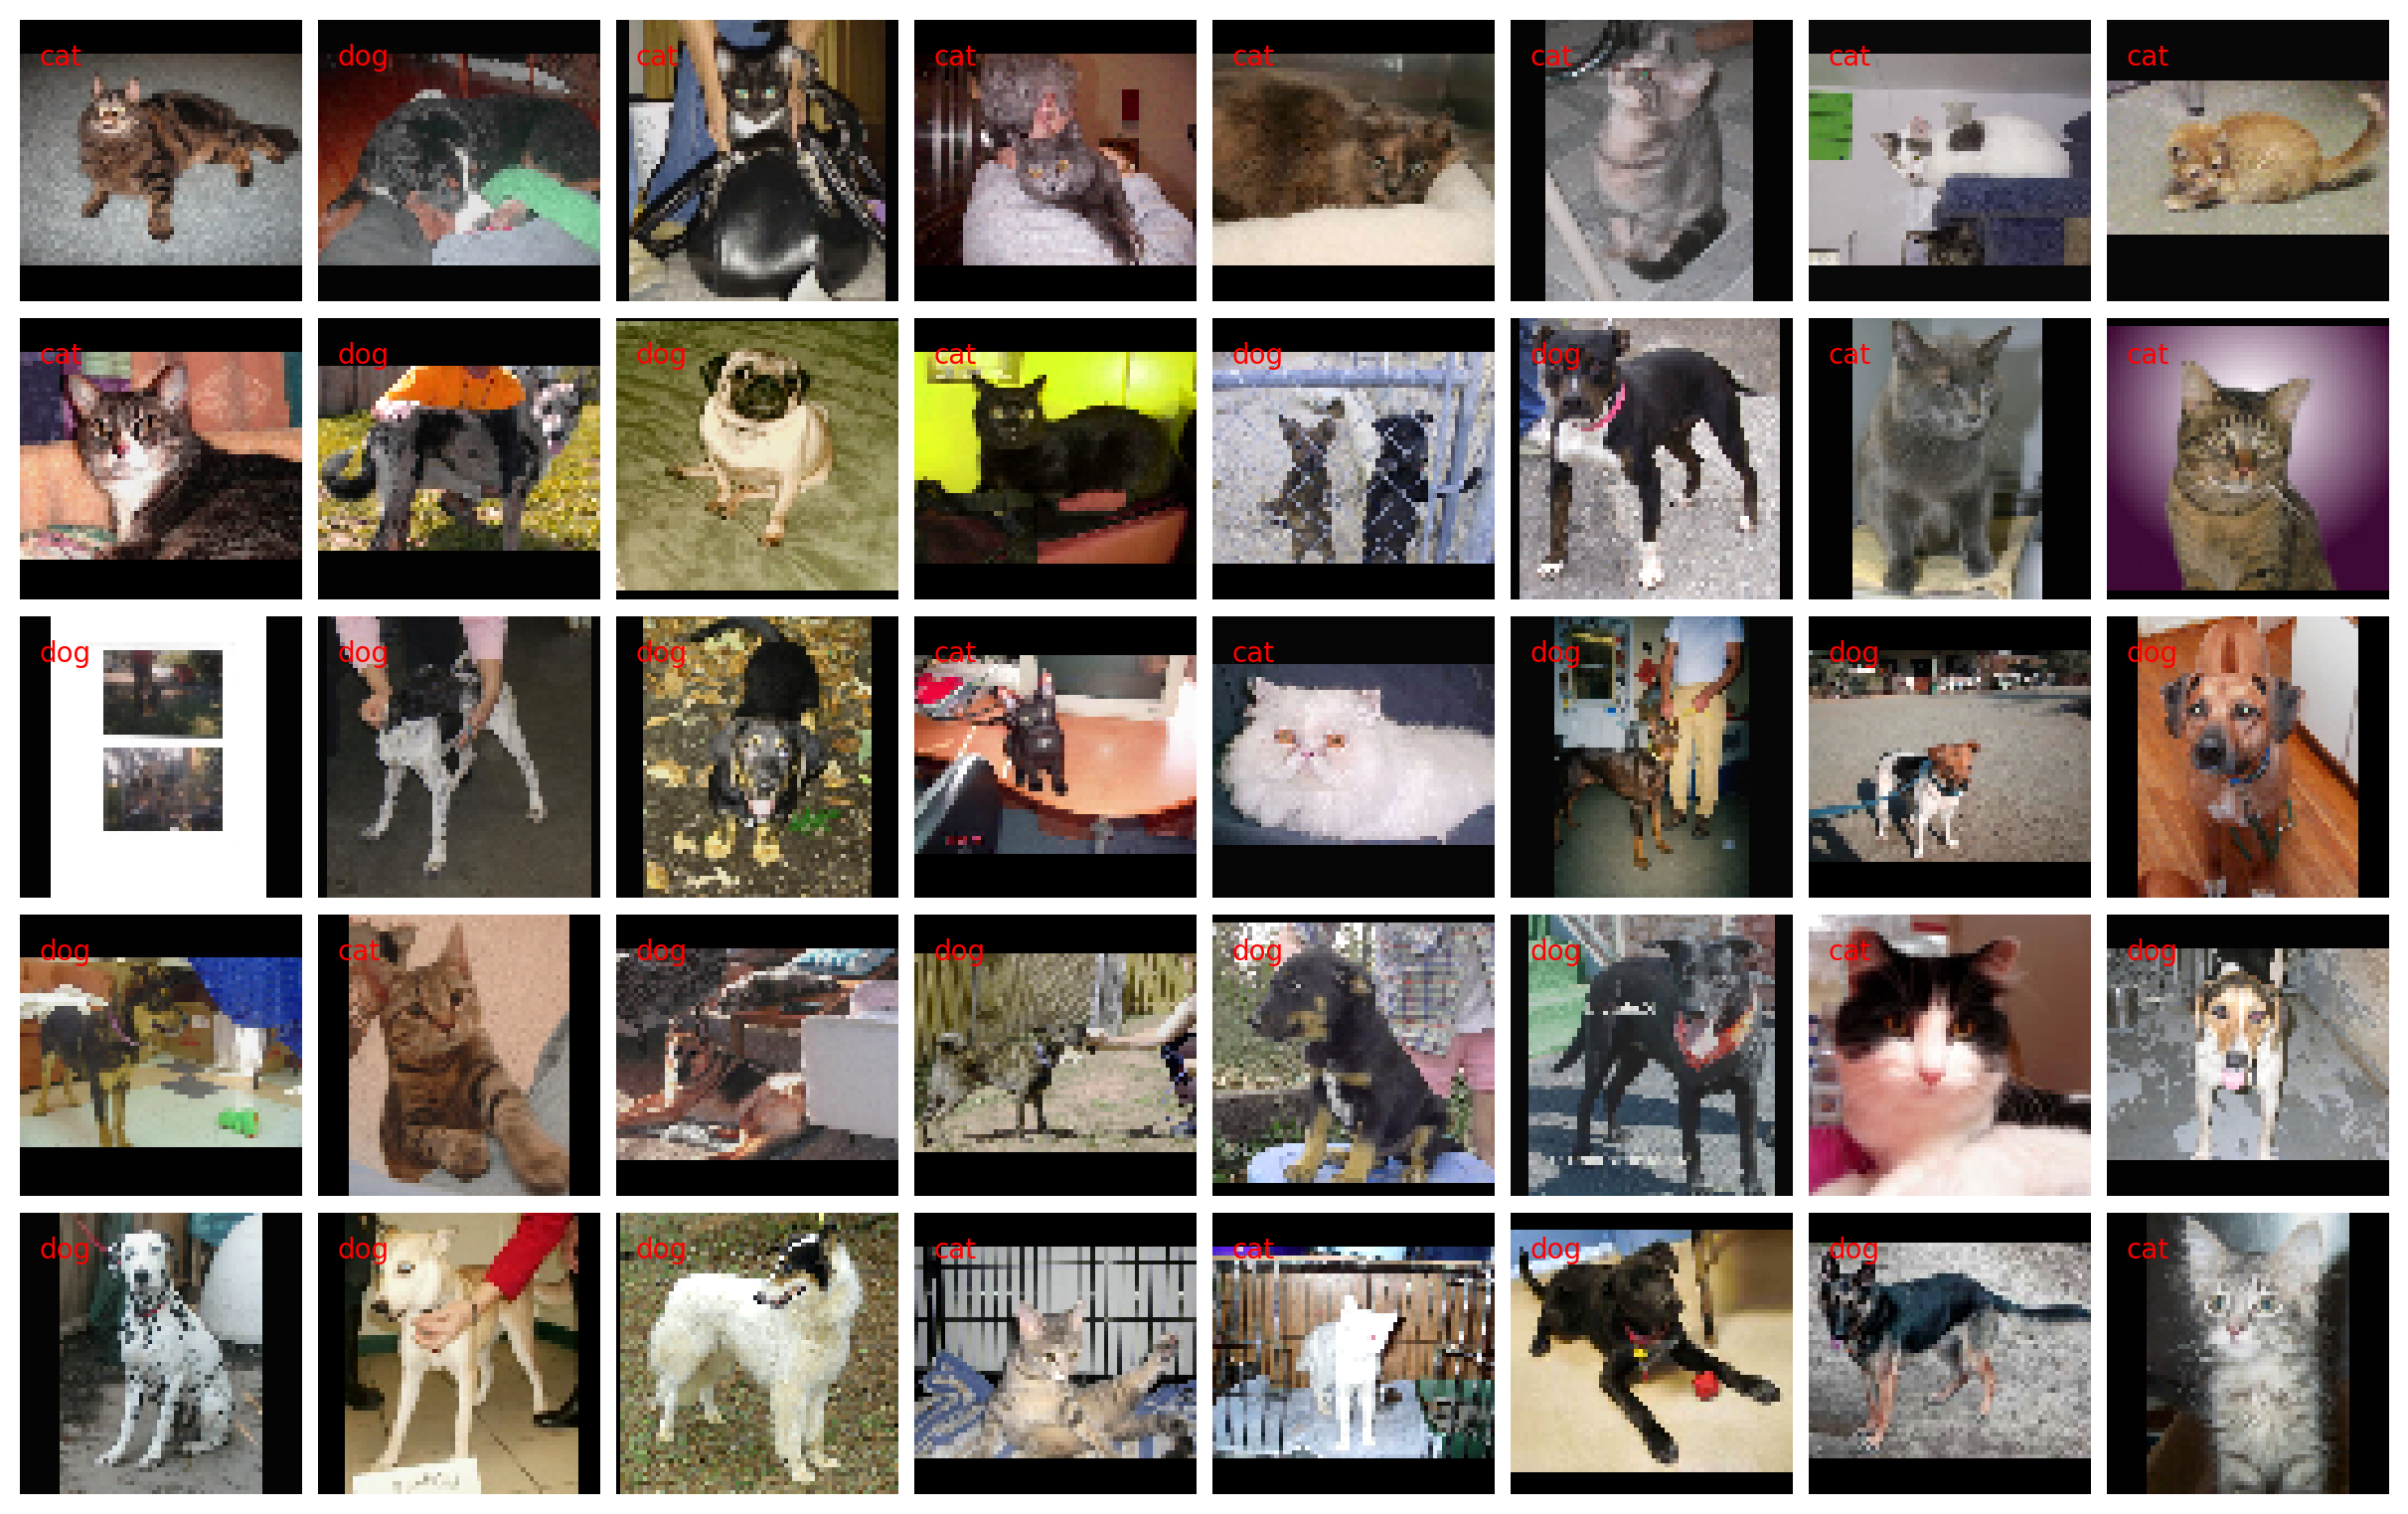

In [10]:
from helper import *

class_text = ["cat","dog"]
raw_image_size = 64
image_size = 64

v_width = 8; v_height = 5
nb_images_per_iter = v_width*v_height

#See Albumentation documentation for a list of existing augmentations
train_transform = A.Compose([
  #A.Affine(scale=(...,...), keep_ratio=False, rotate=(...,...), interpolation=1),
  A.Resize(height=image_size, width=image_size, interpolation=1, p=1.0),
  A.ColorJitter(brightness=(0.9,1.1), contrast=(0.9,1.1), saturation=(0.9,1.1), hue=0.05, p=1.0),
  A.ToGray(p=0.02),
  A.HorizontalFlip(p=0.5),
])

val_transform = A.Compose([
    A.Resize(height=image_size, width=image_size, interpolation=1),
])

data_prep(nb_images_per_iter, raw_image_size, image_size)
input_data, targets = create_augmented_batch(train_transform)

fig, ax = plt.subplots(v_height, v_width, figsize=(v_width*1.5,v_height*1.5), dpi=200, constrained_layout=True)
patch = np.zeros((image_size,image_size,3), dtype="uint8")

for i in range(0, v_width*v_height):
  c_x = i // v_width; c_y = i % v_width
  #Images in the augmented input_data array are directly in the CIANNA format.
  #We need to convert them back to classical RGB for display.
  for depth in range(0,3):
    patch[:,:,depth] = np.reshape(input_data[i,depth*image_size**2:(depth+1)*image_size**2]*155 + 100,(image_size,image_size))

  ax[c_x,c_y].imshow(patch)
  ax[c_x,c_y].text(4, 10, class_text[(np.argmax(targets[i]))], c="red", fontsize=10, clip_on=True)
  ax[c_x,c_y].axis('off')

plt.show()

free_data_helper()

#### Training a network

The following cell trains a very simple LeNET-5-inspired network on the ASIRRA dataset at a low resolution of 32x32. This network will be very fast at training and inference, but it can only reach a low classification accuracy.

As stated at the beginning of the notebook, **your objective is to find an architecture that maximizes classification accuracy, while keeping the inference time under 300 ms**.

The only limiting rules are not to use external data or pretrained models on another dataset, not to change the data split between training and validation/test, and to run inference on a T4 GPU on Colab to measure inference time.
Other than that, you are free to:
 * Change the input image resolution
 * Modify/expand the augmentation policy
 * Modify/expand the network backbone

To stimulate your search, we provide a shared [Google Sheet](https://docs.google.com/spreadsheets/d/1l3l5zfHfAsi5AF4IU4P-5OQs0nl4cRzQpoHdWkRBqUc/edit?usp=sharing) to be used as a dynamic leaderboard. You can tackle this part individually, in pairs, or by forming teams. Once you have a working model, you can enter its properties/results in the leaderboard. It will only be accessible for the duration of this course.

**Some strategies to help you explore model architectures:**
 * 1) Try to add layers in the network backbone and evaluate their impact on accuracy and compute time.
 * 2) Use the provided table of performance per layer to identify bottlenecks in your architecture (Remember that a layer's performance is not only dictated by its own parameters but also by the shape of its input, which depends on the configuration of the previous layer).
 * 3) When increasing the number of parameters in your architecture (number of layers or their size), you will be more prone to overtraining (test set error increasing). For this reason, changes to the architecture should be accompanied by changes to your image augmentation policy. Overtraining can be monitored by following the "fwd mean loss" reported by CIANNA, which is computed on the validation dataset (identical to the test dataset in our case). The validation error as a function of the epoch is also reported in the *error.txt* file that is created automatically by CIANNA.
 * 4) Increasing the image size is a good way to improve accuracy, but there is a diminishing return at some point. However, this will have a strong negative impact on your computing time. Try to reduce the activation maps' resolution more aggressively over a few layers when using higher input resolutions. Keep an eye on the receptive field of the convolutional part of your backbone.

**Points to keep an eye on:**
 * The size of the last activation maps before your first dense layer will have a strong impact on the number of parameters in your model, but it will not necessarily correlate with its accuracy. Keep an eye on the size of your activation maps before the first dense layer. You could also try to build a fully convolutional architecture to get rid of dense layers. This also has the advantage of making your trained model "compatible" with many input image resolutions. Again, the receptive field will be very important with such architecture. Examples are available in the CIANNA repository (see the ImageNET network backbone).
 * The batch size has a direct effect on the compute speed of your model, with larger values allowing faster computing (up to some limit). However, you are limited by the amount of GPU memory used by your model. Also, in this exercise, speed only matters at inference time. In contrast, small batch sizes are usually preferable during training to achieve higher accuracy and converge in fewer training steps.
 * Using mixed precision is also an efficient way to increase computing speed, but it can reduce the accuracy (usually by only a small amount). Unless you choose to use a very deep architecture, you will likely achieve better results with FP16C_FP32A activated for both training and inference.
 * Finally, use existing knowledge available regarding architecture design. You are free to be inspired by any architecture you know or find. You will find architecture examples in the CIANNA repository, but you are free to explore various architecture designs (AlexNET, VGG, DenseNET, YOLO/darknet, etc), as long as the required layers are available in CIANNA.

*Link to the [CIANNA](https://github.com/Deyht/CIANNA) repository. You can refer to CIANNA's [website](https://cianna.obspm.fr/) for a complete framework description. You can also look at the full [API documentation](https://cianna.obspm.fr/content/API/API.html)-Interface-API-documentation) to add layer types that are absent from the LeNET-5 example.
The saved models are available in the "net_save" repository that is automatically created when starting network training. The default naming scheme only refers to the training iteration, so rename your saving files with comprehensive information about your model to keep track of your progress. A saved model can be uploaded to a new Colab session for inference or further training.*

In [ ]:

%%bash

python3 - <<EOF

from helper import *

raw_image_size = 64
image_size = 64
nb_images_per_iter = 4096

load_iter = 0

# Data augmentation
train_transform = A.Compose([
  A.Resize(height=image_size, width=image_size, interpolation=1, p=1.0),
  A.ColorJitter(brightness=(0.85,1.15), contrast=(0.85,1.15),
                saturation=(0.85,1.15), hue=0.05, p=0.8),
  A.ToGray(p=0.02),
  A.HorizontalFlip(p=0.5),
  A.Affine(scale=(0.9,1.1), rotate=(-10,10),
           interpolation=1, p=0.3),
])

val_transform = A.Compose([
    A.Resize(height=image_size, width=image_size, interpolation=1),
])

def data_augm():
  input_data, targets = create_augmented_batch(train_transform)
  cnn.delete_dataset("TRAIN_buf", silent=1)
  cnn.create_dataset("TRAIN_buf", nb_images_per_iter,
                     input_data[:,:], targets[:,:], silent=1)
  return

cnn.init(b_size=32, optimizer=cnn.rms_prop(momentum=0.9), wema=0, dynamic_load=1,
  comp_meth='C_BLAS', mixed_precision="FP16C_FP32A")

data_prep(nb_images_per_iter, raw_image_size, image_size)

input_val, targets_val = create_validation_set(val_transform)
cnn.create_dataset("VALID", 2048, input_val[:,:], targets_val[:,:])
cnn.create_dataset("TEST", 2048, input_val[:,:], targets_val[:,:])

input_data, targets = create_augmented_batch(train_transform)
cnn.create_dataset("TRAIN", nb_images_per_iter, input_data[:,:], targets[:,:])

a_relu = cnn.relu(leaking=0.05, saturation=640000.0)

if(load_iter > 0):
  cnn.input(spatial_shape=[image_size,image_size,1], nb_features=3)
  cnn.load("net_save/net0_s%04d.dat"%load_iter, load_iter, nb_skip_layers=1, bin=1)
else:
  cnn.input(spatial_shape=[image_size,image_size,1], nb_features=3)

  # Block 1
  cnn.conv(f_size=(3,3), nb_filters=16, padding=(1,1), activation=a_relu)
  cnn.conv(f_size=(3,3), nb_filters=16, padding=(1,1), activation=a_relu)
  cnn.pool(p_size=(2,2), p_type="MAX")

  # Block 2
  cnn.conv(f_size=(3,3), nb_filters=32, padding=(1,1), activation=a_relu)
  cnn.conv(f_size=(3,3), nb_filters=32, padding=(1,1), activation=a_relu)
  cnn.pool(p_size=(2,2), p_type="MAX")

  # Block 3
  cnn.conv(f_size=(3,3), nb_filters=64, padding=(1,1), activation=a_relu)
  cnn.pool(p_size=(2,2), p_type="MAX")

  # Classifier
  cnn.dense(nb_neurons=256, activation=a_relu, drop_rate=0.5)
  cnn.dense(nb_neurons=128, activation=a_relu, drop_rate=0.3)
  cnn.dense(nb_neurons=2, strict_size=1, activation="SMAX")


warmup = 10
cycle_length = 500
nb_cycles = 1

l_r_max = 3e-4
l_r_min = 3e-6

nb_iter_per_augm = 1
if(nb_iter_per_augm > 1):
  shuffle_frequency = 1
else:
  shuffle_frequency = 0

for i in range(load_iter, nb_cycles*cycle_length):

  if((i+1) % nb_iter_per_augm == 0):
    t = Thread(target=data_augm)
    t.start()

  if(i < warmup):
    l_r = l_r_min + (l_r_max - l_r_min) * min(i/warmup,1.0)
  else:
    cycle_id = i//cycle_length
    in_cycle_progress = (i%cycle_length)/cycle_length
    l_r = l_r_min + 0.5*(l_r_max*0.8**cycle_id - l_r_min)*(1 + np.cos(np.pi*in_cycle_progress))

  cnn.train(nb_iter=1, learning_rate=l_r, weight_decay=0.01, decoupled_wdecay=1,
    confmat=1, control_interv=50, save_every=100, save_optim_every=100,
    save_bin=1, TC_scale_factor=128.0, shuffle_every=shuffle_frequency)

  if(i == 0):
    cnn.perf_eval()

  if((i+1) % nb_iter_per_augm == 0):
    t.join()
    cnn.swap_data_buffers("TRAIN")

free_data_helper()

EOF



                  ..:^~!?JY5PB~                                                                                         
          J5PGB#&&&&&#BGP55YY#&#!                                                                                       
          &GGB##&&&@@@@@&#PJ?B#&B                                                                                       
         .&#&@@@@@@@@@@@@@@@B##&G                                                                                       
       ^G@@@@BJ^.   .~?P&@@@@@&&G                                                                                       
     &&@@@B^   :!???^^..:7&@@@@&G      .~~~         :~~:         ~~~^        ~~~    ~~~^        ~~~         ^~~.        
   .B@@@&^  !#@@@@@@@@&?^~J&@@@@B ^    !@@@.       :@@@@^       .@@@@G      .@@@:  .@@@@P      .@@@:       ~@@@@.       
  .&@@@#  .J@@@#GP55PB&@&JJ5@@@@B ^G   !@@@.       &@@@@@.      .@@@@@&:     @@@:  .@@@@@&:    .@@@.      :@@@@@&       
  &@@@@.  ?@@&Y?JJJJJJJP@5JY@@@

#### Evaluate your model

The following cell evaluates the accuracy and inference time over the test set.

Colab usually puts the GPU into sleep mode after idling for a few seconds. Always run this cell a few times in a row to get the real execution time.

Edit the Google Sheet to add your result:  
https://docs.google.com/spreadsheets/d/1l3l5zfHfAsi5AF4IU4P-5OQs0nl4cRzQpoHdWkRBqUc/edit?usp=sharing

In [15]:
%%bash

python3 - <<EOF
from helper import *

raw_image_size = 64
image_size = 64

val_transform = A.Compose([
    A.Resize(height=image_size, width=image_size, interpolation=1),
])

cnn.init(b_size=32, inference_only=1, dynamic_load=1,
  comp_meth='C_BLAS', mixed_precision="FP32C_FP32A")

data_prep(0, raw_image_size, image_size, test_mode=1)

#Compute on only half the validation set to reduce memory footprint
input_test, targets_test = create_validation_set(val_transform)
cnn.create_dataset("TEST", 2048, input_test[:,:], targets_test[:,:])


#Change epochs to load based on your own training
load_epoch = 500
if(load_epoch == 0):
  #You can also load an arbitrary named save state
  #Use in combination with nb_skip_layers=1 in load
  #to allow change of input resolution for fully convolutional networks
  cnn.input(spatial_shape=[image_size,image_size,1], nb_features=3)
  cnn.load("...", 0, nb_skip_layers=1, bin=1, silent=1)
else:
  cnn.input(spatial_shape=[image_size,image_size,1], nb_features=3)
  cnn.load("net_save/net0_s%04d.dat"%load_epoch, load_epoch, nb_skip_layers=1, bin=1, silent=1)


#Run forward a first time to wake up the GPU and save the result
pred_result = cnn.forward(drop_mode="AVG_MODEL", no_error=1, saving=0, return_output=1)

start = time.perf_counter()
#Run forward to evaluate raw model performance
cnn.forward(drop_mode="AVG_MODEL", no_error=1, saving=0, return_output=0)
end = time.perf_counter()

cnn.perf_eval()

compute_time = (end-start)*1000 #in miliseconds

pred_correct = np.shape(np.where(np.argmax(pred_result[:,:2], axis=1) == np.argmax(targets_test[:,:], axis=1)))[1]
pred_accuracy = (pred_correct/2048)*100.0

sys.stdout.flush()

print ("Inference time: %f ms (%d ips)"%(compute_time, int(2048/(compute_time/1000))))
print ("Accuracy: %f, Error rate: %f"%(pred_accuracy, 100.0-pred_accuracy))

free_data_helper()

EOF


                  ..:^~!?JY5PB~                                                                                         
          J5PGB#&&&&&#BGP55YY#&#!                                                                                       
          &GGB##&&&@@@@@&#PJ?B#&B                                                                                       
         .&#&@@@@@@@@@@@@@@@B##&G                                                                                       
       ^G@@@@BJ^.   .~?P&@@@@@&&G                                                                                       
     &&@@@B^   :!???^^..:7&@@@@&G      .~~~         :~~:         ~~~^        ~~~    ~~~^        ~~~         ^~~.        
   .B@@@&^  !#@@@@@@@@&?^~J&@@@@B ^    !@@@.       :@@@@^       .@@@@G      .@@@:  .@@@@P      .@@@:       ~@@@@.       
  .&@@@#  .J@@@#GP55PB&@&JJ5@@@@B ^G   !@@@.       &@@@@@.      .@@@@@&:     @@@:  .@@@@@&:    .@@@.      :@@@@@&       
  &@@@@.  ?@@&Y?JJJJJJJP@5JY@@@